In [3]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [4]:
df_DA_US=df[(df['job_title']=='Data Analyst') & (df['job_country']=='United States')].copy()

In [5]:
df_DA_US['job_posted_month_no'] = df_DA_US['job_posted_date'].dt.month

In [6]:
df_DA_US_explode = df_DA_US.explode('job_skills')

In [25]:
df_DA_US_Pivot = df_DA_US_explode.pivot_table(index='job_posted_month_no',columns='job_skills',aggfunc='size',fill_value=0)

df_DA_US_Pivot.loc['Total'] = df_DA_US_Pivot.sum()

df_DA_US_Pivot = df_DA_US_Pivot[df_DA_US_Pivot.loc['Total'].sort_values(ascending=False).index]

df_DA_US_Pivot = df_DA_US_Pivot.drop('Total')

<Axes: xlabel='job_posted_month_no'>

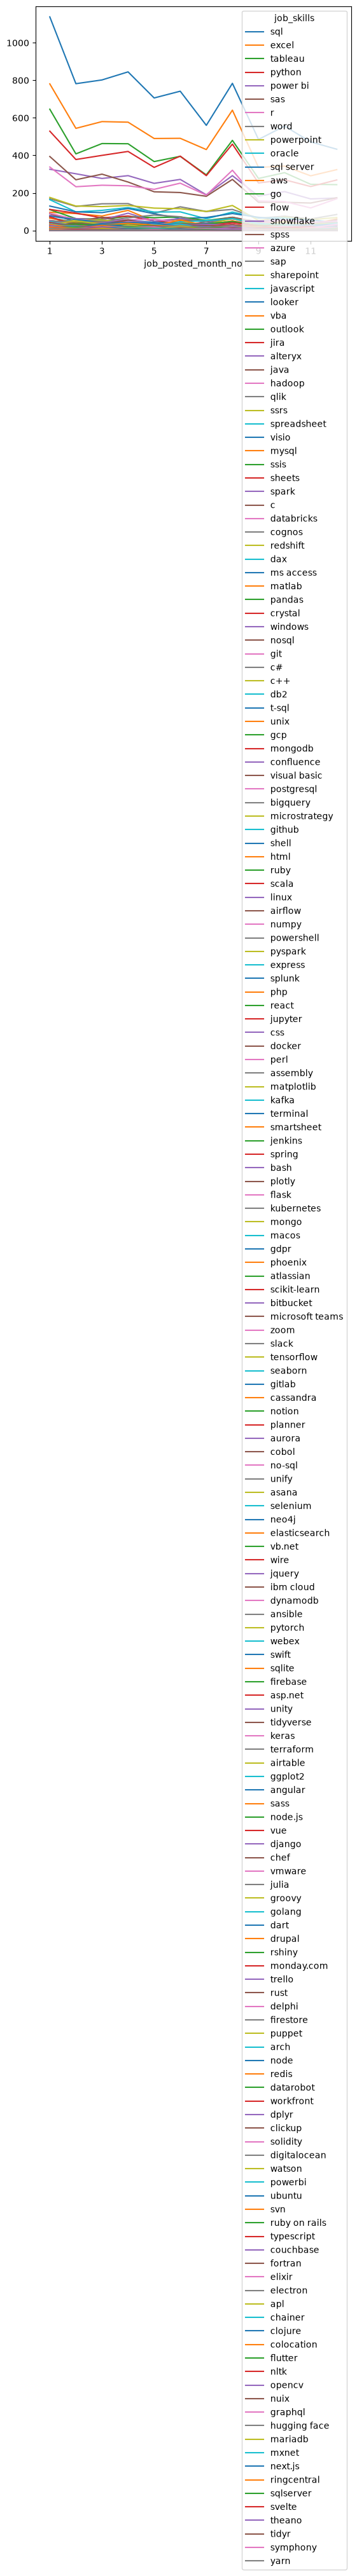

In [26]:
df_DA_US_Pivot.plot(kind='line')

In [27]:
DA_totals = df_DA_US.groupby('job_posted_month_no').size()

In [39]:
df_DA_US_Perc=df_DA_US_Pivot.div(DA_totals/100,axis=0)
df_DA_US_Perc

job_skills,sql,excel,tableau,python,power bi,sas,r,word,powerpoint,oracle,...,mariadb,mxnet,next.js,ringcentral,sqlserver,svelte,theano,tidyr,symphony,yarn
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,62.665198,43.006608,35.572687,29.129956,17.951542,21.696035,18.612335,9.306167,9.691630,9.030837,...,0.000000,0.000000,0.000000,0.055066,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
2,60.903427,42.367601,31.775701,29.439252,23.520249,21.028037,18.146417,9.968847,10.124611,7.710280,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
3,58.883994,42.584435,33.994126,29.368576,20.337739,22.026432,17.694567,10.425844,9.324523,7.856094,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
4,61.723886,42.147553,33.747261,30.752374,21.329438,18.845873,17.384953,10.445581,9.715121,8.911614,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
5,61.072664,42.387543,31.747405,29.065744,21.712803,17.820069,18.944637,7.958478,10.294118,8.477509,...,0.086505,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
6,61.474731,40.679370,32.725766,32.808616,22.535211,16.735708,20.878210,10.439105,9.610605,8.202154,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
7,58.638743,45.130890,30.994764,30.575916,19.895288,19.057592,19.685864,10.575916,10.575916,6.492147,...,0.000000,0.000000,0.104712,0.000000,0.104712,0.000000,0.000000,0.0000,0.000000,0.104712
8,55.445545,45.332390,33.946252,32.531825,20.650636,19.236209,22.701556,7.920792,9.405941,6.930693,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000
9,56.658879,39.252336,32.359813,29.556075,21.378505,17.523364,18.341121,7.593458,6.191589,7.827103,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.116822,0.000000


In [40]:
df_DA_US_Perc=df_DA_US_Perc.reset_index()
df_DA_US_Perc['job_posted_month']=df_DA_US_Perc['job_posted_month_no'].apply(lambda x: pd.to_datetime(x,format='%m').strftime('%b'))
df_DA_US_Perc = df_DA_US_Perc.set_index('job_posted_month')
df_DA_US_Perc=df_DA_US_Perc.drop(columns='job_posted_month_no')


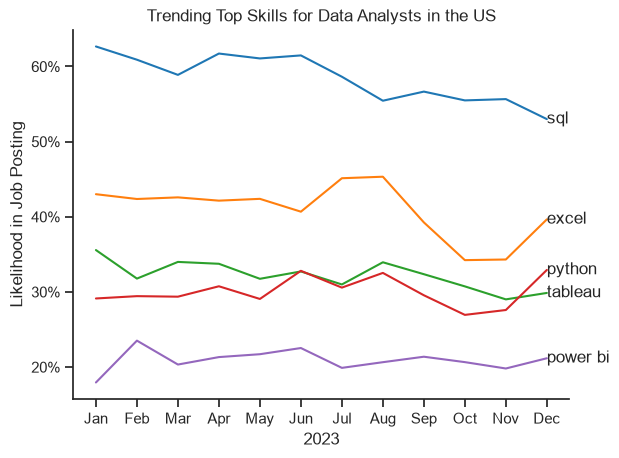

In [53]:
df_plot = df_DA_US_Perc.iloc[:, :5]

sns.lineplot(data=df_plot, dashes=False, palette='tab10')
sns.despine()
for column in df_plot.columns:
    plt.text(
        x=df_plot.index[-1],      
        y=df_plot[column].iloc[-1],  
        s=column,                 
        va='center'
    )

plt.title('Trending Top Skills for Data Analysts in the US')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')
plt.legend().remove()

from matplotlib.ticker import PercentFormatter
ax=plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.show()

